# **Baseline MVP**

Runs the full end-to-end pipeline on sample images and validates:
- Pipeline produces correct text output
- Confidence gate silences low-confidence results
- Reading order is natural (top→bottom, left→right)
- End-to-end latency stays within 2s budget

**No logic lives here** — everything imports from `src/`.

This notebook is a harness for validation and visualization only.

## 1. Mount Drive & Install

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import subprocess, sys
def pip(pkg): subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

pip("python-doctr[torch]")
pip("transformers")
pip("pyyaml")
pip("gtts")     # cloud TTS — no audio device needed on Colab

print("Done — restart runtime and continue from cell 3.")

Done — restart runtime and continue from cell 3.


## 2. Paths & sys.path

In [2]:
import sys
from pathlib import Path

# src/ and configs/ live at the capstone root on Drive
DRIVE_ROOT   = Path("/content/drive/MyDrive/vision-ocr-accessibility-assistant")
PROJECT_ROOT = DRIVE_ROOT

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SAMPLE_DIR  = DRIVE_ROOT / "data/processed/benchmark_sample"
IMG_DIR     = SAMPLE_DIR / "images"
RESULTS_DIR = DRIVE_ROOT / "outputs/results"
FIGURES_DIR = DRIVE_ROOT / "outputs/figures"
MODEL_CACHE = DRIVE_ROOT / "models/trocr"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert (PROJECT_ROOT / "src").exists(),     "src/ not found — upload to Drive first"
assert (PROJECT_ROOT / "configs").exists(), "configs/ not found — upload to Drive first"
print("Paths OK ")

Paths OK 


In [4]:
import subprocess, sys
def pip(pkg): subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

pip("typer==0.9.0")
pip("click==8.1.7")

print("Done — restart runtime, then rerun from cell 3")

Done — restart runtime, then rerun from cell 3


## 3. Load Pipeline

In [3]:
import torch
from src.pipeline import Pipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

# cloud backend: gTTS generates MP3 bytes instead of playing audio
pipe = Pipeline(
    device=DEVICE,
    tts_backend="cloud",
    model_cache_dir=str(MODEL_CACHE)
)

Device: cuda
Loading detector (db_resnet50) on cuda...
Detector ready
Loading recognizer (TrOCR) on cuda...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

Recognizer ready   (334M parameters)

Pipeline ready 
  Confidence gate : 0.75
  Latency budget  : 2.0s
  TTS backend     : cloud


## 4. Run on 10 Sample Images

In [4]:
import json, random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

random.seed(42)

with open(SAMPLE_DIR / "detection_sample.json") as f:
    detection_sample = json.load(f)

samples     = random.sample(detection_sample, 10)
all_results = []

for i, s in enumerate(samples):
    img_path = IMG_DIR / s["file_name"]
    print(f"\n[{i+1}/10] {s['file_name']}")
    result = pipe.run(img_path)
    result["file_name"] = s["file_name"]
    all_results.append(result)

print("\n All images processed")


[1/10] COCO_train2014_000000367222.jpg
Gate (0.75): 2 spoken, 5 silenced
TTS speaking: ['ITEM', 'SPURT']

Latency breakdown:
  Detection   : 462.2ms
  Recognition : 949.9ms
  Total       : 1758.1ms  ✓

[2/10] COCO_train2014_000000367171.jpg
Gate (0.75): 6 spoken, 2 silenced
TTS speaking: ['SIR', 'MATT', 'BUSBY', '0', '9', 'WAY']

Latency breakdown:
  Detection   : 171.0ms
  Recognition : 618.4ms
  Total       : 1657.8ms  ✓

[3/10] COCO_train2014_000000290168.jpg
Gate (0.75): 0 spoken, 7 silenced
TTS: nothing to speak (all gated)

Latency breakdown:
  Detection   : 120.3ms
  Recognition : 590.2ms
  Total       : 717.5ms  ✓

[4/10] COCO_train2014_000000106010.jpg
Gate (0.75): 1 spoken, 6 silenced
TTS speaking: ['OPEN']

Latency breakdown:
  Detection   : 133.8ms
  Recognition : 658.1ms
  Total       : 1000.0ms  ✓

[5/10] COCO_train2014_000000045464.jpg
Gate (0.75): 1 spoken, 3 silenced
TTS: nothing to speak (punctuation only)

Latency breakdown:
  Detection   : 131.7ms
  Recognition : 2

## 5. Latency Summary

In [6]:
import pandas as pd

lat_df = pd.DataFrame([{
    "file":           r["file_name"],
    "detection_ms":   r["latency"]["detection_s"]   * 1000,
    "recognition_ms": r["latency"]["recognition_s"] * 1000,
    "total_ms":       r["latency"]["total_s"]       * 1000,
    "within_budget":  r["latency"]["within_budget"],
    "n_spoken":       r["n_spoken"],
    "n_silenced":     r["n_silenced"],
} for r in all_results])

print(lat_df.to_string(index=False))
print(f"\nMean total : {lat_df['total_ms'].mean():.1f}ms")
print(f"Max  total : {lat_df['total_ms'].max():.1f}ms")
print(f"All within budget: {lat_df['within_budget'].all()}")

lat_df.to_csv(RESULTS_DIR / "03_mvp_latency.csv", index=False)
print("Saved ")

                           file  detection_ms  recognition_ms  total_ms  within_budget  n_spoken  n_silenced
COCO_train2014_000000367222.jpg         462.2           949.9    1758.1           True         2           5
COCO_train2014_000000367171.jpg         171.0           618.4    1657.8           True         6           2
COCO_train2014_000000290168.jpg         120.3           590.2     717.5           True         0           7
COCO_train2014_000000106010.jpg         133.8           658.1    1000.0           True         1           6
COCO_train2014_000000045464.jpg         131.7           259.6     399.9           True         1           3
COCO_train2014_000000106836.jpg         116.8            90.1     916.6           True         0           1
COCO_train2014_000000332013.jpg         117.6           539.8    2548.0          False         6           1
COCO_train2014_000000548010.jpg         123.7           511.6    1965.3           True         5           2
COCO_train2014_0000

## 6. Visual Output 
 Boxes Colored by Gate Status

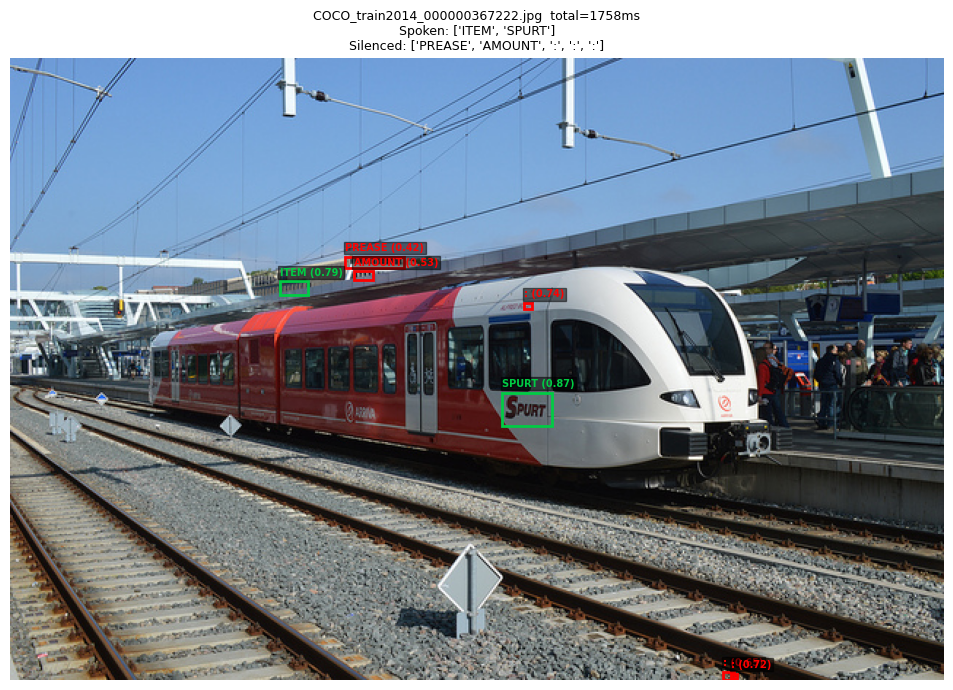

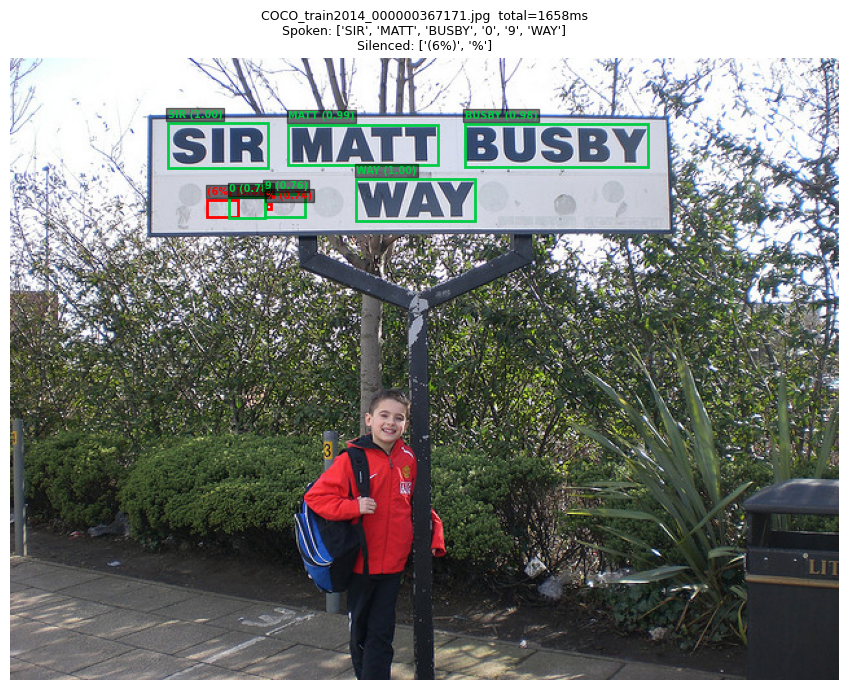

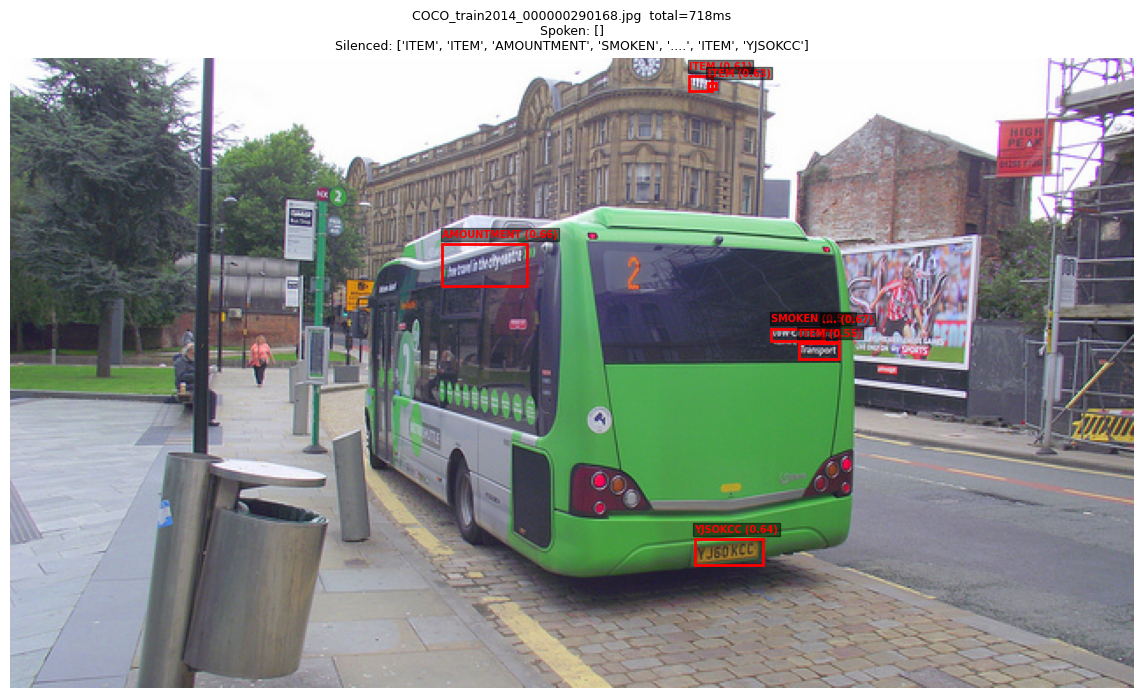

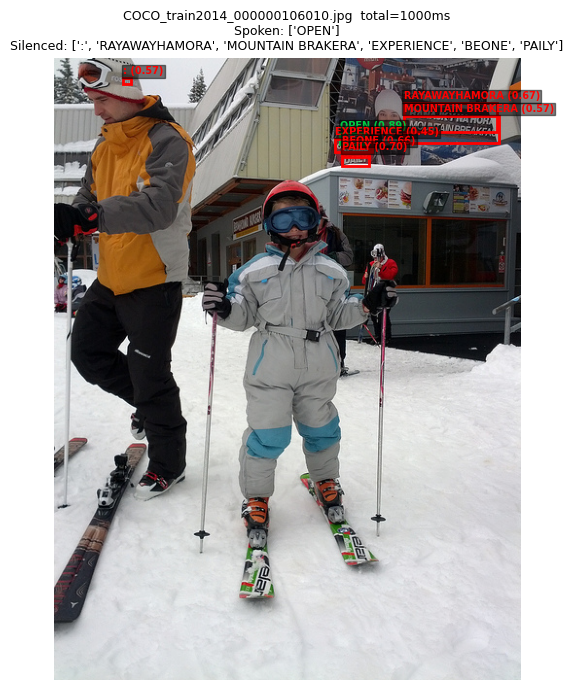

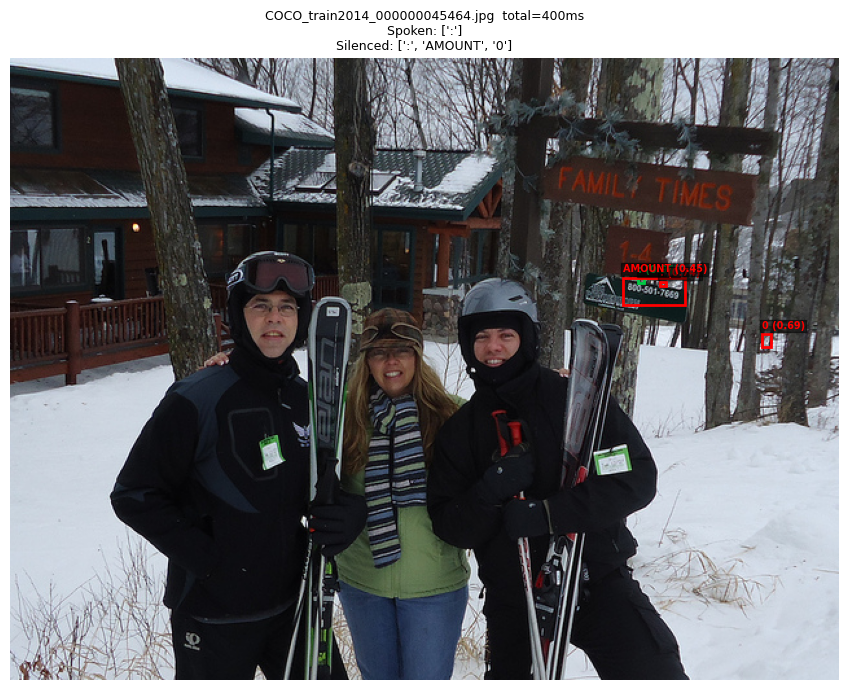

In [7]:
# Green box = spoken  (confidence >= 0.75)
# Red box   = silenced (confidence < 0.75)

for result in all_results[:5]:
    img_pil = Image.open(IMG_DIR / result["file_name"]).convert("RGB")
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(img_pil); ax.axis("off")

    for r in result["gated_results"]:
        x, y, w, h = r["box"]
        color = "red" if r["gated"] else "#00cc44"
        ax.add_patch(patches.Rectangle((x,y), w, h,
            linewidth=2, edgecolor=color, facecolor="none"))
        ax.text(x, y-4,
            f"{r['text']} ({r['confidence']:.2f})",
            color=color, fontsize=7, fontweight="bold",
            bbox=dict(facecolor="black", alpha=0.5, pad=1))

    spoken   = [r["text"] for r in result["gated_results"] if not r["gated"]]
    silenced = [r["text"] for r in result["gated_results"] if r["gated"]]
    ax.set_title(
        f"{result['file_name']}  total={result['latency']['total_s']*1000:.0f}ms\n"
        f"Spoken: {spoken}\nSilenced: {silenced}", fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"03_mvp_{result['file_name']}", dpi=120, bbox_inches="tight")
    plt.show()

## 7. Reading Order Validation

In [8]:
print("Reading order output per image:\n")
for result in all_results:
    spoken = [r["text"] for r in result["gated_results"] if not r["gated"]]
    print(f"  {result['file_name']}")
    print(f"  → {' | '.join(spoken) if spoken else '(nothing spoken)'}")
    print()

Reading order output per image:

  COCO_train2014_000000367222.jpg
  → ITEM | SPURT

  COCO_train2014_000000367171.jpg
  → SIR | MATT | BUSBY | 0 | 9 | WAY

  COCO_train2014_000000290168.jpg
  → (nothing spoken)

  COCO_train2014_000000106010.jpg
  → OPEN

  COCO_train2014_000000045464.jpg
  → :

  COCO_train2014_000000106836.jpg
  → (nothing spoken)

  COCO_train2014_000000332013.jpg
  → BUPLISH | YAHOO! | ROAD | TO | 382 | HISTORY

  COCO_train2014_000000548010.jpg
  → 65 | 66 | 67 | BAAGS | :

  COCO_train2014_000000198037.jpg
  → (nothing spoken)

  COCO_train2014_000000412141.jpg
  → (nothing spoken)



## 8. Gate Statistics

Total regions  : 50
Spoken         : 21  (42.0%)
Silenced       : 29  (58.0%)
Mean confidence: 0.728


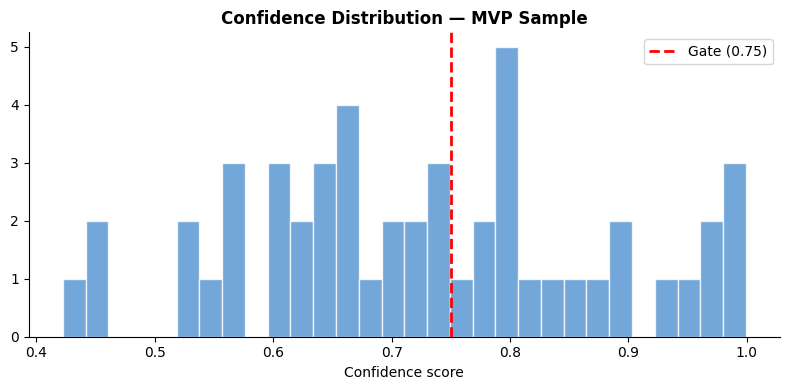

Saved 


In [9]:
all_gated = [r for res in all_results for r in res["gated_results"]]
total     = len(all_gated)
spoken    = sum(1 for r in all_gated if not r["gated"])
confs     = [r["confidence"] for r in all_gated]

print(f"Total regions  : {total}")
print(f"Spoken         : {spoken}  ({spoken/total*100:.1f}%)")
print(f"Silenced       : {total-spoken}  ({(total-spoken)/total*100:.1f}%)")
print(f"Mean confidence: {sum(confs)/len(confs):.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(confs, bins=30, color="#5090d0", edgecolor="white", alpha=0.8)
ax.axvline(pipe.conf_threshold, color="red", linestyle="--",
           lw=2, label=f"Gate ({pipe.conf_threshold})")
ax.set_xlabel("Confidence score")
ax.set_title("Confidence Distribution — MVP Sample", fontweight="bold")
ax.legend(); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_mvp_confidence_dist.png", dpi=150)
plt.show()
print("Saved ")

## 9. Phase 3 Sign-off

In [10]:
print("=" * 52)
print(" BASELINE MVP SIGN-OFF")
print("=" * 52)

checks = [
    (lat_df["within_budget"].all(), "All images within 2s latency budget"),
    (lat_df["n_spoken"].mean() > 0, "Pipeline speaks at least some text per image"),
    (total > 0,                     "Confidence gate is active"),
]

all_pass = True
for ok, label in checks:
    print(f"  {'✓' if ok else '✗'} {label}")
    if not ok: all_pass = False

print()
if all_pass:
    print("  → Phase 3 complete. Proceed to Phase 4: Full Benchmarking.")
else:
    print("  → Fix failing checks before proceeding.")

 BASELINE MVP SIGN-OFF
  ✗ All images within 2s latency budget
  ✓ Pipeline speaks at least some text per image
  ✓ Confidence gate is active

  → Fix failing checks before proceeding.


> ⚠️ total_ms includes gTTS network latency (cloud TTS placeholder).

> True pipeline latency = detection_ms + recognition_ms.

> gTTS will be replaced with async TTS in Phase 5/6.